# Separating temporal and spatial errors

**Source:** CompSci §§4.3, 5.2.1, pp. 25–27, 40–42 · [Source map](../docs/SOURCES.md) · [Course index](../README.md)

For a smooth periodic sine wave solving $c_t=c_{xx}$, the exact continuum eigenvalue is $\lambda=-4\pi^2$. The centred discrete Laplacian gives $\lambda_h=-4\sin^2(\pi/N)/\Delta x^2$. Comparing $e^{t\lambda_h}$ with $e^{t\lambda}$ isolates spatial error. Comparing a time integrator with $e^{t\lambda_h}$ isolates temporal error. Combined errors can cancel, so a small total error alone does not identify either contribution.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22,
                     "axes.spines.top": False, "axes.spines.right": False})
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "01_Foundations").is_dir() and (p / "requirements.txt").is_file())
out = root / "assets" / "figures"
out.mkdir(parents=True, exist_ok=True)

def show(fig, name):
    fig.tight_layout()
    fig.savefig(out / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


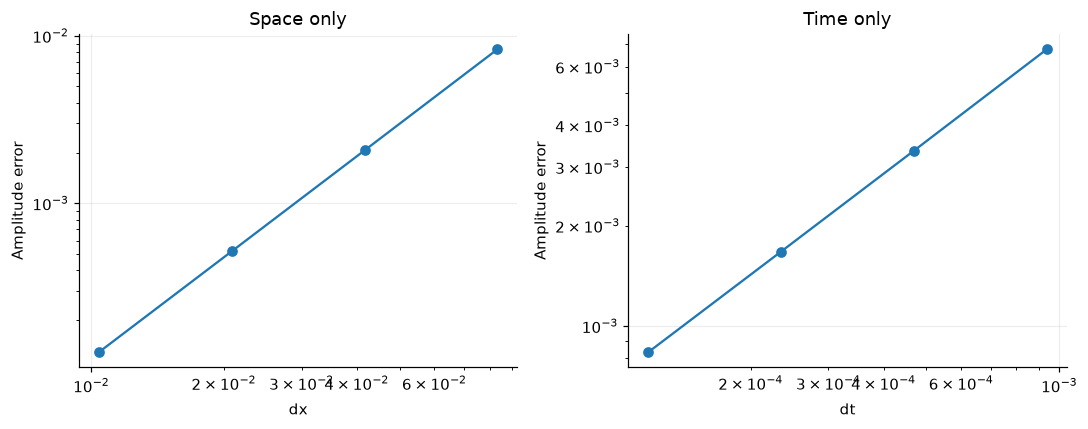

In [2]:
T=.03; ns=np.array([12,24,48,96]); lam=-4*np.pi**2
lh=-4*ns**2*np.sin(np.pi/ns)**2
spatial=abs(np.exp(T*lh)-np.exp(T*lam))
steps=np.array([32,64,128,256]); h=T/steps
l=lh[1]
temporal=abs((1+h*l)**steps-np.exp(T*l))
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].loglog(1/ns,spatial,"o-"); ax[0].set(xlabel="dx",ylabel="Amplitude error",title="Space only")
ax[1].loglog(h,temporal,"o-"); ax[1].set(xlabel="dt",ylabel="Amplitude error",title="Time only")
show(fig,"05-error-budget")
assert abs(np.log2(spatial[-2]/spatial[-1])-2)<.03
assert abs(np.log2(temporal[-2]/temporal[-1])-1)<.03

## Worked exercise

**Why do we compare with the semidiscrete solution for the time sweep?** At fixed spatial resolution it is the exact answer for the ODE actually being integrated. Comparing with the continuum would eventually show a spatial-error floor.